# Credit Card Fraud Detection Using Machine Learning

## Project Overview

The objective of this project is to build and evaluate machine learning models capable of detecting fraudulent credit card transactions.

Because fraud datasets are highly imbalanced, special attention is given to:
- **Imbalance handling that is compared, not assumed**: no resampling vs class weights vs SMOTE vs undersampling
- **Leakage-free, time-ordered evaluation**: train on the past, validate and test on the future
- **Metrics beyond accuracy**: PR-AUC, MCC, share of fraud *value* caught, recall at a fixed alert budget, bootstrap confidence intervals
- **A cost-aware decision threshold** that uses real transaction amounts
- **Calibration, error analysis and SHAP explanations**

## Workflow

1. Imports
2. Data Exploration
3. Data Quality Assessment
4. Exploratory Data Analysis (EDA)
5. Data Preprocessing: feature engineering and out-of-time split
6. Modeling Pipelines and imbalance-handling ablation
7. Model Comparison and Tuning
8. Threshold Selection (cost-based)
9. Test Set Evaluation (with confidence intervals)
10. Probability Calibration
11. Error Analysis
12. Explainability (SHAP)
13. Saving the Model
14. Conclusion, Limitations and Next Steps

## 1. Imports

In [2]:
import warnings
warnings.filterwarnings('ignore')

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap                                     
from IPython.display import display, Markdown
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             precision_recall_curve, PrecisionRecallDisplay, roc_auc_score,
                             RocCurveDisplay)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier             

RANDOM_STATE = 42

## 2. Data Exploration

### Dataset

The dataset contains anonymized credit card transactions made by European cardholders over two days.

**Features:**
- **V1–V28**: Principal components obtained using PCA
- **Time**: Seconds elapsed between each transaction and the *first* transaction in the dataset (not a clock time)
- **Amount**: Transaction amount
- **Class**:
  - 0 → Legitimate Transaction
  - 1 → Fraudulent Transaction

The dataset is highly imbalanced, making fraud detection a challenging classification problem.

In [3]:
# Load the credit card transactions dataset
df = pd.read_csv('../data/creditcard.csv')

# Display basic information about the dataset
print("Dataset Shape:", df.shape)
print("\n--- Dataset Info ---")
df.info()

Dataset Shape: (284807, 31)

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [7]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

## 3. Data Quality Assessment

In [8]:
print(f"Shape: {df.shape}")
print(f"Fraud %: {df['Class'].mean()*100:.3f}%")
print(df['Class'].value_counts())

Shape: (284807, 31)
Fraud %: 0.173%
Class
0    284315
1       492
Name: count, dtype: int64


#### Observation

Only **0.173%** of the transactions are fraudulent.

This confirms that the dataset is **highly imbalanced**, making accuracy an unreliable evaluation metric.

For this reason, precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC will be emphasized later in the project.

In [9]:
# Check for missing values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
# Check for duplicate records
duplicates = df.duplicated().sum()
print(f"Duplicate Records: {duplicates}")

# Remove duplicates before splitting, so identical rows cannot end up in both train and test
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after de-duplication: {df.shape}")
print(df['Class'].value_counts().rename({0: 'Legit', 1: 'Fraud'}).to_string())
print(f"Fraud rate: {df['Class'].mean()*100:.3f}%")

Duplicate Records: 1081
Shape after de-duplication: (283726, 31)
Class
Legit    283253
Fraud       473
Fraud rate: 0.167%


## 4. Exploratory Data Analysis (EDA)

This section explores the dataset to better understand feature distributions, class imbalance, and relationships between variables. These insights help guide preprocessing and model selection.

#### Observations

- Transaction amounts are highly right-skewed, with most transactions involving relatively small amounts.
- A small number of transactions have very large amounts, indicating the presence of outliers.
- Transaction time is spread across the observation period and does not appear uniformly distributed.

Text(0.5, 0, 'Transaction Class')

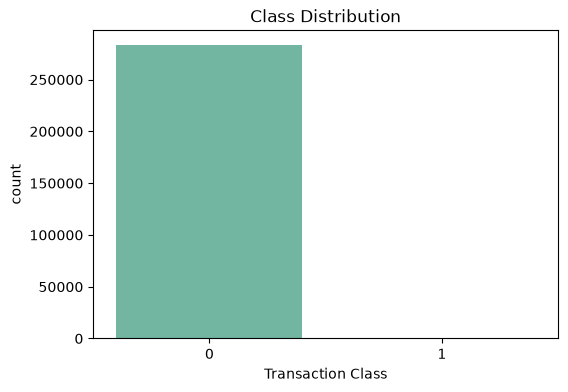

In [11]:
# Visualize the distribution of legitimate and fraudulent transactions
plt.figure(figsize=(6,4))
sns.countplot(x="Class", data=df, palette='Set2')
plt.title("Class Distribution")
plt.xlabel("Transaction Class")

#### Observation

The dataset is extremely imbalanced. Fraudulent transactions account for only about **0.17%** of all observations. Therefore, evaluation metrics such as Precision, Recall, F1-score, and ROC-AUC are more appropriate than accuracy.

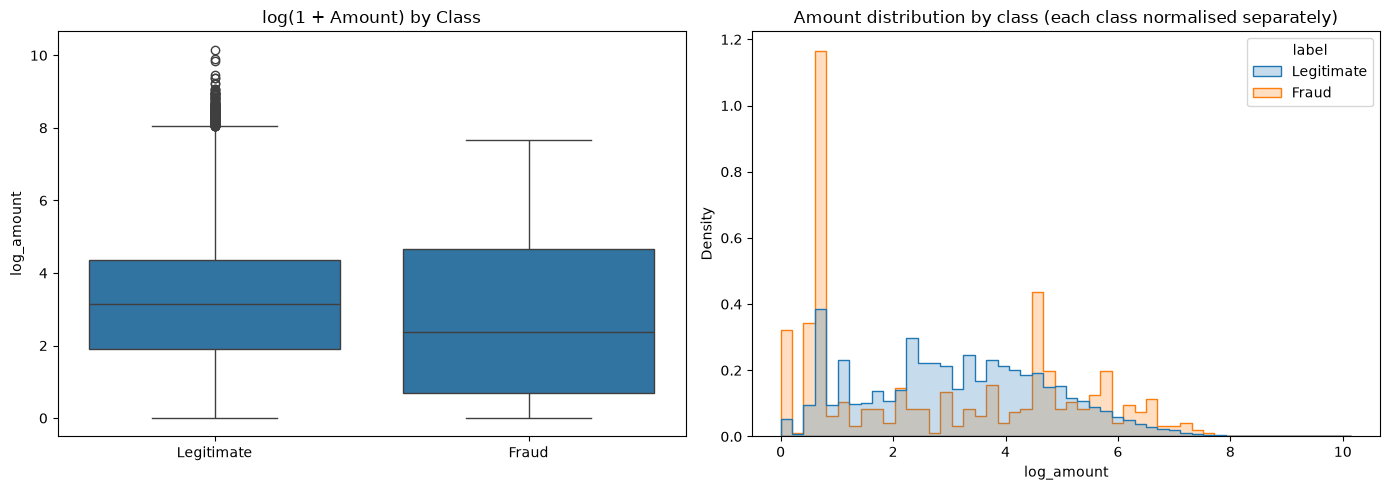

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [12]:
# Compare transaction amounts for legitimate and fraudulent transactions
# Transaction amount by class on a log scale (the raw scale is dominated by a few huge legit transactions)
amt_df = pd.DataFrame({
    'label': df['Class'].map({0: 'Legitimate', 1: 'Fraud'}),
    'log_amount': np.log1p(df['Amount']),
})

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='label', y='log_amount', data=amt_df, order=['Legitimate', 'Fraud'], ax=ax[0])
ax[0].set_title('log(1 + Amount) by Class')
ax[0].set_xlabel('')
sns.histplot(data=amt_df, x='log_amount', hue='label', hue_order=['Legitimate', 'Fraud'],
             stat='density', common_norm=False, bins=50, element='step', ax=ax[1])
ax[1].set_title('Amount distribution by class (each class normalised separately)')
plt.tight_layout()
plt.show()

display(df.groupby('Class')['Amount'].describe().round(2))

(0.0, 172792.0)

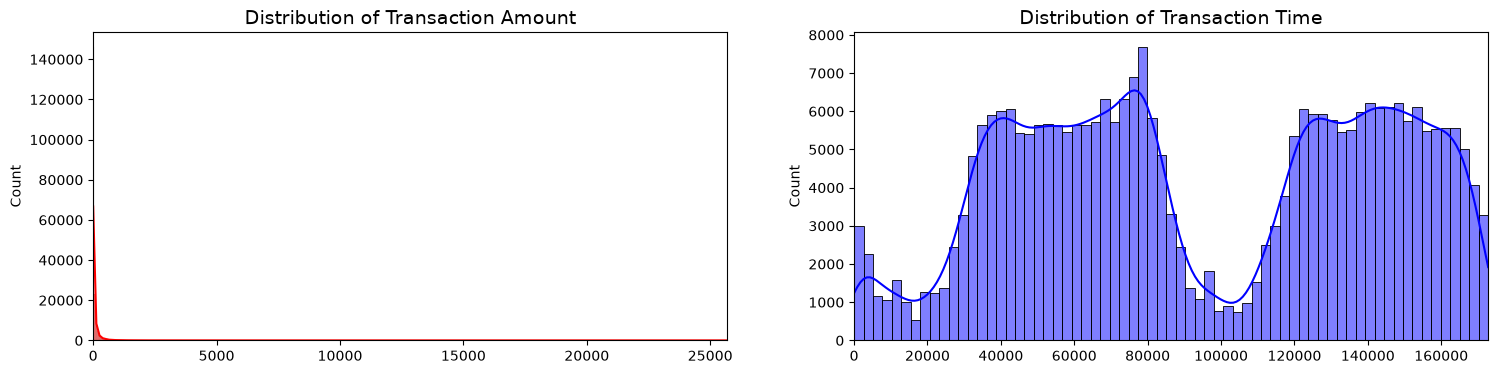

In [13]:
# Create two subplots to visualize the distributions of transaction amount and transaction time
fig, ax = plt.subplots(1, 2, figsize=(18,4))

# The amount and time features
amount_val = df['Amount'].values
time_val = df['Time'].values

# Transaction amount distribution
sns.histplot(amount_val, ax=ax[0], color='r', kde=True)
ax[0].set_title('Distribution of Transaction Amount', fontsize=14)
ax[0].set_xlim([min(amount_val), max(amount_val)])

# Transaction time distribution
sns.histplot(time_val, ax=ax[1], color='b', kde=True)
ax[1].set_title('Distribution of Transaction Time', fontsize=14)
ax[1].set_xlim([min(time_val), max(time_val)])

- V1 to V28 are PCA components, so they are uncorrelated by construction and correalation heatmap will be almost entirely blank. A sorted bar chart of correlation with Class is more informative.

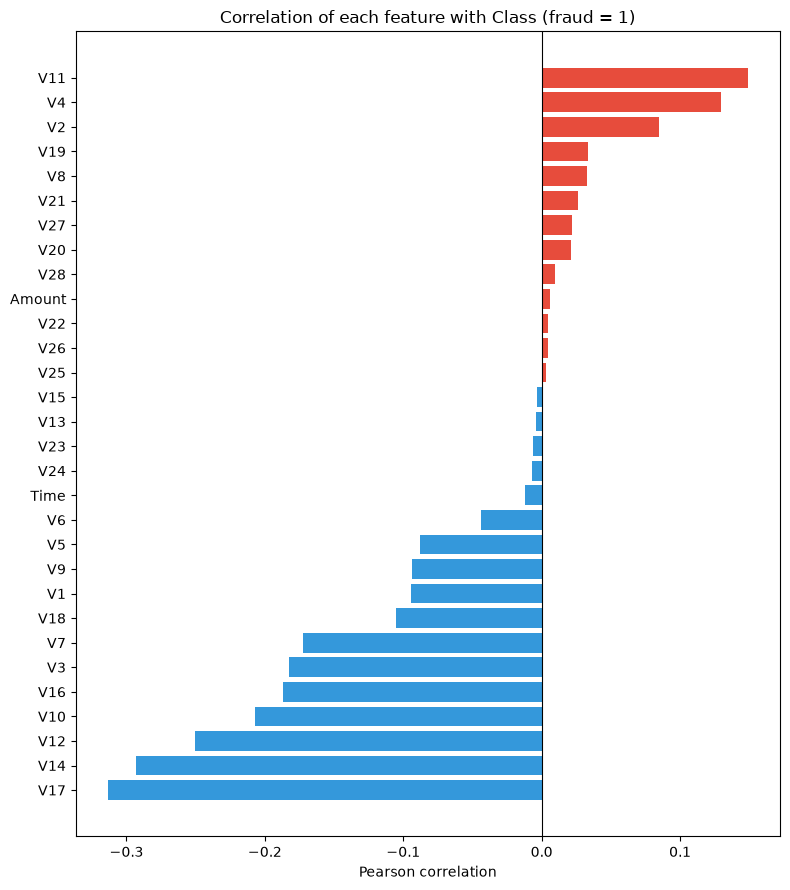

In [14]:
# Correlation of every feature with the target, sorted
corr_with_class = df.corr(numeric_only=True)['Class'].drop('Class').sort_values()

plt.figure(figsize=(8, 9))
plt.barh(corr_with_class.index, corr_with_class.values,
         color=['#3498db' if v < 0 else '#e74c3c' for v in corr_with_class.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of each feature with Class (fraud = 1)')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

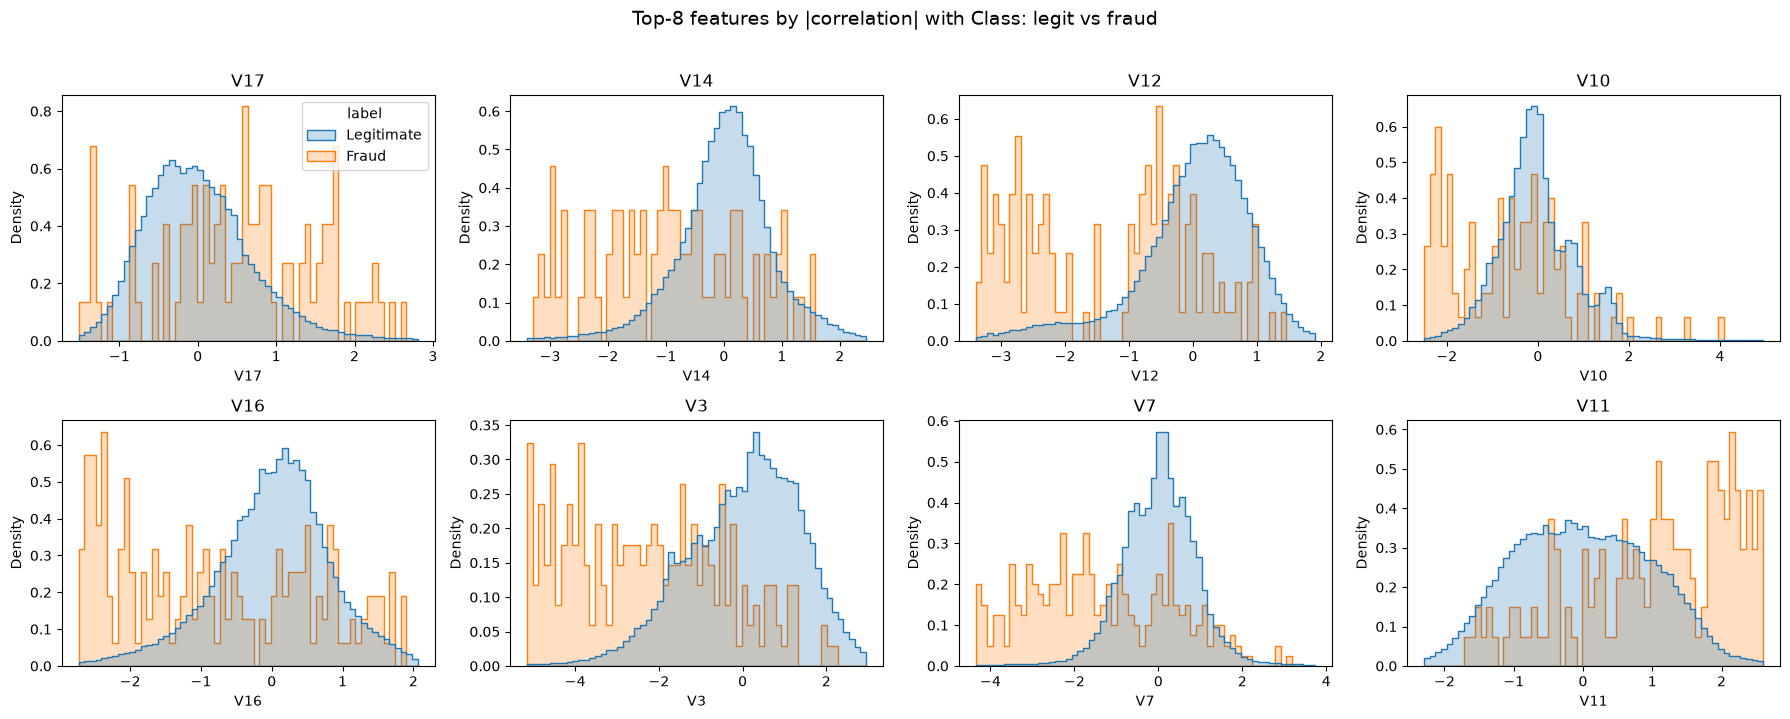

In [15]:
# Distribution of the 8 features most correlated with Class, fraud vs legit (each class normalised separately)
corr_abs = df.corr(numeric_only=True)['Class'].drop('Class').abs()
top_feats = corr_abs.sort_values(ascending=False).head(8).index.tolist()
feat_df = df[top_feats].assign(label=df['Class'].map({0: 'Legitimate', 1: 'Fraud'}))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for f, ax in zip(top_feats, axes.ravel()):
    lo, hi = df[f].quantile([0.005, 0.995])                    # zoom to the bulk of the data
    sns.histplot(data=feat_df, x=f, hue='label', hue_order=['Legitimate', 'Fraud'], stat='density',
                 common_norm=False, bins=60, binrange=(lo, hi), element='step', ax=ax,
                 legend=(f == top_feats[0]))
    ax.set_title(f)
plt.suptitle('Top-8 features by |correlation| with Class: legit vs fraud', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

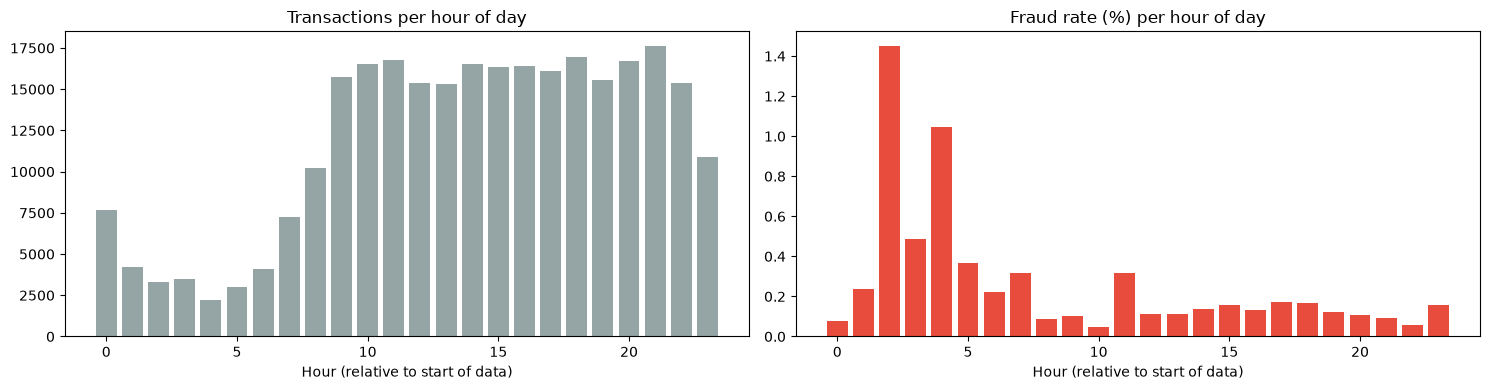

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
transactions,7647.000,4208.000,3308.000,3487.000,2204.000,2988.000,4082.00,7233.000,10232.000,15767.000,...,16520.000,16374.000,16396.000,16130.000,16959.000,15566.000,16705.000,17629.000,15378.000,10883.000
frauds,6.000,10.000,48.000,17.000,23.000,11.000,9.00,23.000,9.000,16.000,...,23.000,26.000,22.000,28.000,28.000,19.000,18.000,16.000,9.000,17.000
fraud_rate_%,0.078,0.238,1.451,0.488,1.044,0.368,0.22,0.318,0.088,0.101,...,0.139,0.159,0.134,0.174,0.165,0.122,0.108,0.091,0.059,0.156


In [16]:
# Volume and fraud rate by hour of day. Time is "seconds since the first transaction",
# so the hour is relative to the start of the data, not wall-clock time.
hour_of_day = ((df['Time'] // 3600) % 24).astype(int).rename('hour')
by_hour = df.groupby(hour_of_day).agg(transactions=('Class', 'size'), frauds=('Class', 'sum'))
by_hour['fraud_rate_%'] = 100 * by_hour['frauds'] / by_hour['transactions']

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(by_hour.index, by_hour['transactions'], color='#95a5a6')
ax[0].set_title('Transactions per hour of day')
ax[0].set_xlabel('Hour (relative to start of data)')
ax[1].bar(by_hour.index, by_hour['fraud_rate_%'], color='#e74c3c')
ax[1].set_title('Fraud rate (%) per hour of day')
ax[1].set_xlabel('Hour (relative to start of data)')
plt.tight_layout()
plt.show()

display(by_hour.T.round(3))

### EDA takeaways

- **Imbalance:** only ~0.17 % of transactions are fraud, so accuracy is meaningless. PR-AUC, precision/recall and value-based metrics are used instead.
- **Amount:** heavily right-skewed (note the log scale). Fraud amounts tend to be small, so Amount alone separates the classes poorly (see the per-class table). It still matters for *cost*, because a missed fraud costs its amount, so it is used in the threshold selection (section 8).
- **Time:** the histogram shows a clear day/night cycle, and `Time` is "seconds since the first transaction", not a clock time. Raw `Time` cannot generalise to a later period, so section 5 replaces it with cyclical hour-of-day features.
- **Features:** V1–V28 are PCA components, so they are uncorrelated with each other and no single one separates fraud well. That is why the sorted bar chart replaces the 30×30 heatmap. The features most correlated with `Class` should reappear as the most important ones in the SHAP analysis (section 12).
- **Hour of day:** the fraud *rate* per hour is noisy (only a few dozen frauds per hourly bucket) and is often highest in the quiet hours, when legitimate volume is low. Treat it as a weak signal.

## 5. Data Preprocessing

### 5.1 Features
- **`Time` → cyclical hour of day (`hour_sin`, `hour_cos`).** Raw `Time` is "seconds since the first transaction" and only grows, so in a time-ordered split the test period lies outside anything seen in training, and tree models cannot extrapolate. The daily cycle seen in the EDA is the reusable signal. Sin/cos encoding makes 23:59 and 00:01 neighbours.
- **`Amount` → `log_amount = log(1 + Amount)`** to tame the heavy right tail (helps linear models, harmless for trees). The raw amounts are kept aside, only for cost and value-based metrics.
- **V1–V28** are used as they are (already PCA components).
- Feature creation is stateless (nothing is learned from the data), so doing it before the split cannot leak information.


In [17]:
def make_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Raw columns (Time, V1..V28, Amount) -> model features. Stateless, so it is safe to apply before splitting."""
    out = raw[[f'V{i}' for i in range(1, 29)]].copy()
    out['log_amount'] = np.log1p(raw['Amount'])
    tod = (raw['Time'] % 86400) / 86400                  # position inside the 24 h cycle, 0..1
    out['hour_sin'] = np.sin(2 * np.pi * tod)
    out['hour_cos'] = np.cos(2 * np.pi * tod)
    return out

### 5.2 Out-of-time (OOT) split
Transactions are sorted by `Time` and split **70 % train / 15 % validation / 15 % test**.

A random split can train on transactions that happen *after* some of the test transactions, which never happens in production. Here:
- **Train** = the past. Everything is fitted on it.
- **Validation** = the next block. Used for model selection, tuning and the decision threshold.
- **Test** = the "far future". Used once, at the end.

In [18]:
# Sort chronologically: never train on the future of the data you test on
df_sorted = df.sort_values('Time', kind='stable').reset_index(drop=True)
X_all, y_all = make_features(df_sorted), df_sorted['Class']
amount_all = df_sorted['Amount']                         # raw amounts, kept for cost / value-based metrics only

n_rows = len(df_sorted)
train_end, val_end = int(n_rows * 0.70), int(n_rows * 0.85)

X_train, y_train = X_all.iloc[:train_end], y_all.iloc[:train_end]
X_val, y_val, amt_val = X_all.iloc[train_end:val_end], y_all.iloc[train_end:val_end], amount_all.iloc[train_end:val_end].values
X_test, y_test, amt_test = X_all.iloc[val_end:], y_all.iloc[val_end:], amount_all.iloc[val_end:].values
raw_test = df_sorted.iloc[val_end:]                      # raw columns of the test block (used to verify the saved model)

split_summary = pd.DataFrame({
    'rows': [len(X_train), len(X_val), len(X_test)],
    'frauds': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    'fraud_rate_%': [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],
    'starts_at_hour': [df_sorted['Time'].iloc[0] / 3600, df_sorted['Time'].iloc[train_end] / 3600,
                       df_sorted['Time'].iloc[val_end] / 3600],
}, index=['Train (past)', 'Validation', 'Test (future)'])
display(split_summary.round(3))
print(f'{X_train.shape[1]} features: V1-V28 + {list(X_train.columns[28:])}   (raw Time and raw Amount are not used)')

,rows,frauds,fraud_rate_%,starts_at_hour
Train (past),198608,366,0.184,0.000
Validation,42559,55,0.129,36.918
Test (future),42559,52,0.122,42.033


31 features: V1-V28 + ['log_amount', 'hour_sin', 'hour_cos']   (raw Time and raw Amount are not used)



## 6. Modeling Pipelines

### One imbalance fix per pipeline
The earlier version combined SMOTE with `class_weight='balanced'` / `scale_pos_weight`. SMOTE already makes the training classes 1:1, so class weights on top of it either do nothing (`balanced` → all weights equal 1) or double-count the imbalance (`scale_pos_weight ≈ 600` after SMOTE). That also made the XGBoost comparison unfair. Every pipeline below uses exactly **one** of:

| strategy | what it does |
|---|---|
| `none` | train on the raw, imbalanced data |
| `class_weight` | re-weights the loss (`class_weight='balanced'` or `scale_pos_weight`) |
| `smote` | adds synthetic fraud samples (training folds only, because it sits inside the pipeline) |
| `undersample` | randomly drops legit rows to 10 legit : 1 fraud |

Feature scaling is applied only for logistic regression. Tree models are scale-invariant, which also keeps the SHAP plots in original feature units.

The shared helper functions defined next (cost curve, `evaluate`, F-beta threshold, alert-budget recall) are reused in sections 7 to 9.

In [19]:
# Class ratio (legit : fraud) in the training block. Only used by strategy 'class_weight' for XGBoost / LightGBM.
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


def build_pipeline(kind, strategy):
    """kind: 'lr' | 'rf' | 'xgb' | 'lgbm'.   strategy: 'none' | 'class_weight' | 'smote' | 'undersample'.

    Exactly ONE imbalance fix is applied per pipeline: SMOTE already balances the classes 1:1, so class weights
    on top of it would either do nothing or double-count the imbalance."""
    weighted = strategy == 'class_weight'

    if kind == 'lr':
        model = LogisticRegression(max_iter=2000, class_weight='balanced' if weighted else None,
                                   random_state=RANDOM_STATE)
    elif kind == 'rf':
        model = RandomForestClassifier(n_estimators=100, class_weight='balanced' if weighted else None,
                                       n_jobs=-1, random_state=RANDOM_STATE)
    elif kind == 'xgb':
        model = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=pos_weight if weighted else 1.0, n_jobs=-1, random_state=RANDOM_STATE)
    elif kind == 'lgbm':
        model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, scale_pos_weight=pos_weight if weighted else 1.0,
                               n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
    else:
        raise ValueError(f'unknown model kind: {kind}')

    steps = [('scaler', StandardScaler())] if kind == 'lr' else []         # trees are scale-invariant
    if strategy == 'smote':
        steps.append(('sampler', SMOTE(random_state=RANDOM_STATE)))
    elif strategy == 'undersample':
        steps.append(('sampler', RandomUnderSampler(sampling_strategy=0.1, random_state=RANDOM_STATE)))   # 10 legit : 1 fraud
    steps.append(('model', model))
    return Pipeline(steps)

In [20]:
REVIEW_COST = 5.0   # ASSUMPTION: cost (same units as Amount) of reviewing one alert = analyst time + customer friction. Adjust it.


def cost_curve(y, s, amt, review_cost):
    """Expected cost at every possible threshold: each alert costs `review_cost`, each missed fraud costs its Amount.
    Returns (thresholds, costs); a transaction is flagged when score >= threshold."""
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    order = np.argsort(-s, kind='stable')
    y, s, amt = y[order], s[order], amt[order]
    last = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]       # last row of each distinct score, so ties are never split
    caught_value = np.cumsum(amt * y)[last]
    costs = review_cost * (last + 1) + (amt * y).sum() - caught_value
    return s[last], costs


def evaluate(y, s, amt, thr, review_cost=None):
    """Threshold-free (ROC/PR-AUC) and thresholded metrics, including value-based ones."""
    rc = REVIEW_COST if review_cost is None else review_cost
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    pred = s >= thr
    tp = int((pred & (y == 1)).sum());  fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    fraud_value = float((amt * y).sum())
    missed_value = float((amt * y * ~pred).sum())
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {
        'roc_auc': roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan,
        'pr_auc': average_precision_score(y, s) if y.sum() else np.nan,
        'precision': tp / (tp + fp) if tp + fp else np.nan,
        'recall': tp / (tp + fn) if tp + fn else np.nan,
        'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
        'mcc': (tp * tn - fp * fn) / denom if denom else 0.0,
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'fraud_value_caught_%': 100 * (fraud_value - missed_value) / fraud_value if fraud_value else np.nan,
        'alerts_per_10k': 10_000 * pred.mean(),
        'expected_cost': rc * (tp + fp) + missed_value,
    }


def best_fbeta_threshold(y, s, beta):
    """Threshold maximising F-beta (beta=1: F1; beta=2: recall counts twice as much as precision)."""
    p, r, t = precision_recall_curve(y, s)
    f = (1 + beta**2) * p * r / (beta**2 * p + r + 1e-12)
    i = int(np.argmax(f[:-1]))                                     # the last PR point has no threshold
    return float(t[i]), float(f[i])


def recall_at_budget(y, s, amt, frac):
    """If analysts can only review the top `frac` riskiest transactions, what do they catch?"""
    y, s, amt = np.asarray(y), np.asarray(s), np.asarray(amt)
    k = max(1, int(round(frac * len(y))))
    top = np.argsort(-s, kind='stable')[:k]                        # ties are broken arbitrarily
    return {'budget': f'top {frac:.2%}', 'alerts': k, 'precision': y[top].mean(), 'recall': y[top].sum() / y.sum(),
            'fraud_value_caught_%': 100 * (amt[top] * y[top]).sum() / (amt * y).sum()}

### Does resampling help? An ablation

You concluded that scaling + SMOTE + ensembles make the model robust, but SMOTE itself was never tested. Here the same model is trained on the same **time-ordered folds** (`TimeSeriesSplit`: each fold trains on the past and validates on the next block) and only the imbalance strategy changes. Metric: PR-AUC (average precision).

How to read the result:
- Differences smaller than the fold-to-fold spread (`std` in the printout) are noise.
- For tree ensembles, SMOTE often adds little over class weights or no resampling. If so, dropping it simplifies the pipeline and speeds up training.
- The strategy with the best average PR-AUC across the models is used for every candidate in section 7. Override `IMBALANCE` if you prefer another one.

Logistic Regression  none          PR-AUC 0.5547 ± 0.1304   (2s)
Logistic Regression  class_weight  PR-AUC 0.6633 ± 0.1193   (7s)
Logistic Regression  smote         PR-AUC 0.6794 ± 0.1158   (12s)
Logistic Regression  undersample   PR-AUC 0.4692 ± 0.2642   (12s)
Random Forest        none          PR-AUC 0.7412 ± 0.0401   (32s)
Random Forest        class_weight  PR-AUC 0.7351 ± 0.0353   (40s)
Random Forest        smote         PR-AUC 0.7373 ± 0.0463   (78s)
Random Forest        undersample   PR-AUC 0.7171 ± 0.0389   (79s)
LightGBM             none          PR-AUC 0.6219 ± 0.1683   (86s)
LightGBM             class_weight  PR-AUC 0.3740 ± 0.2383   (89s)
LightGBM             smote         PR-AUC 0.7618 ± 0.0432   (96s)
LightGBM             undersample   PR-AUC 0.7563 ± 0.0433   (98s)


model,LightGBM,Logistic Regression,Random Forest
strategy,,,
none,0.6219,0.5547,0.7412
class_weight,0.3740,0.6633,0.7351
smote,0.7618,0.6794,0.7373
undersample,0.7563,0.4692,0.7171


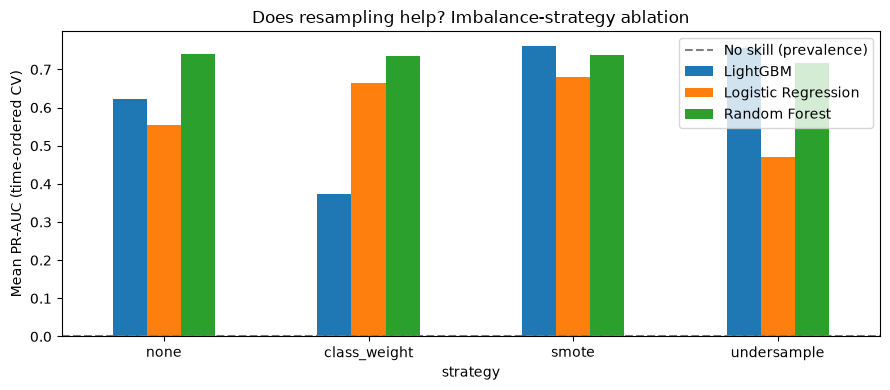


Imbalance strategy used from here on: 'smote'


In [21]:
ABLATE = {'lr': 'Logistic Regression', 'rf': 'Random Forest', 'lgbm': 'LightGBM'}      # drop 'rf' to save time
STRATEGIES = ['none', 'class_weight', 'smote', 'undersample']
cv_time = TimeSeriesSplit(n_splits=3)        # expanding window: train on the past, validate on the next block

rows, t0 = [], time.time()
for kind, label in ABLATE.items():
    for strategy in STRATEGIES:
        scores = cross_val_score(build_pipeline(kind, strategy), X_train, y_train,
                                 cv=cv_time, scoring='average_precision')
        rows.append({'model': label, 'strategy': strategy, 'mean_pr_auc': scores.mean(), 'std': scores.std()})
        print(f'{label:<20} {strategy:<13} PR-AUC {scores.mean():.4f} ± {scores.std():.4f}   ({time.time() - t0:.0f}s)')
ablation = pd.DataFrame(rows)

pivot = ablation.pivot(index='strategy', columns='model', values='mean_pr_auc').loc[STRATEGIES]
display(pivot.round(4))

ax = pivot.plot(kind='bar', figsize=(9, 4), rot=0)
ax.axhline(y_train.mean(), color='gray', linestyle='--', label='No skill (prevalence)')
ax.set_ylabel('Mean PR-AUC (time-ordered CV)')
ax.set_title('Does resampling help? Imbalance-strategy ablation')
ax.legend()
plt.tight_layout()
plt.show()

IMBALANCE = ablation.groupby('strategy')['mean_pr_auc'].mean().idxmax()
# IMBALANCE = 'class_weight'       # <- uncomment to override the automatic choice
print(f"\nImbalance strategy used from here on: '{IMBALANCE}'")

## 7. Model Comparison and Tuning

### 7.1 Candidates and baselines
All candidates are trained on the OOT **train** block and scored on the OOT **validation** block. The test block stays untouched.

- **Logistic Regression, Random Forest, XGBoost, LightGBM** each use the imbalance strategy selected in section 6, so the comparison is fair.
- **Dummy classifier** (always predicts the class prior): the no-skill reference. Its PR-AUC equals the fraud prevalence (~0.0017), which puts a PR-AUC like 0.80 in context.
- **Isolation Forest**: an unsupervised anomaly detector fitted without labels. If a supervised model barely beats it, the labels are adding little.

The earlier cross-validation on a random split is replaced by this time-ordered validation, because random CV can leak the future into the training folds.

In [22]:
KIND = {'Logistic Regression': 'lr', 'Random Forest': 'rf', 'XGBoost': 'xgb', 'LightGBM': 'lgbm'}

fitted, val_scores = {}, {}
for name, kind in KIND.items():
    t0 = time.time()
    pipe = build_pipeline(kind, IMBALANCE).fit(X_train, y_train)
    fitted[name] = pipe
    val_scores[name] = pipe.predict_proba(X_val)[:, 1]
    print(f'{name:<20} fitted in {time.time() - t0:5.1f}s')

# Baselines
dummy = DummyClassifier(strategy='prior').fit(X_train, y_train)                 # no-skill reference
val_scores['Dummy (prior)'] = dummy.predict_proba(X_val)[:, 1]
iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train)      # unsupervised: labels never used
val_scores['Isolation Forest'] = -iso.score_samples(X_val)                      # higher = more anomalous


def rank_table(scores):
    t = pd.DataFrame({n: {'PR-AUC': average_precision_score(y_val, s), 'ROC-AUC': roc_auc_score(y_val, s)}
                      for n, s in scores.items()}).T
    return t.sort_values('PR-AUC', ascending=False)


ranking = rank_table(val_scores)
print(f'\nNo-skill PR-AUC on the validation block = fraud prevalence = {y_val.mean():.4f}')
display(ranking.round(4))

Logistic Regression  fitted in   1.3s
Random Forest        fitted in  33.0s
XGBoost              fitted in   8.2s
LightGBM             fitted in   5.3s

No-skill PR-AUC on the validation block = fraud prevalence = 0.0013


,PR-AUC,ROC-AUC
Random Forest,0.8435,0.9867
Logistic Regression,0.8428,0.9789
XGBoost,0.8024,0.9874
LightGBM,0.7000,0.9741
Isolation Forest,0.0343,0.9471
Dummy (prior),0.0013,0.5000


### 7.2 Hyper-parameter tuning

Everything so far uses near-default hyper-parameters. The best supervised model from the table above gets a small `RandomizedSearchCV`:
- scored on **average precision**, with **time-ordered** folds (`TimeSeriesSplit`)
- a deliberately small budget (`N_ITER`); raise it if you have the time

The tuned model competes with the untuned ones on the validation block, and the winner becomes the **final model**. With only a few dozen validation frauds, gaps of about 0.01 PR-AUC are noise, so prefer the simpler or faster model when results are that close.

### 7.3 Precision-Recall curves of all models
The overlay below includes the no-skill line, so the gap between the models and chance is visible, and the unsupervised baseline for context.

In [23]:
tune_name = ranking.loc[list(KIND), 'PR-AUC'].idxmax()           # best supervised model on the validation block
tune_kind = KIND[tune_name]

param_dists = {
    'lr':   {'model__C': loguniform(1e-3, 1e2)},
    'rf':   {'model__n_estimators': [100, 200, 300], 'model__max_depth': [10, 20, None],
             'model__min_samples_leaf': [1, 2, 5], 'model__max_features': ['sqrt', 0.3]},
    'xgb':  {'model__n_estimators': [200, 400], 'model__max_depth': [3, 4, 6, 8],
             'model__learning_rate': [0.03, 0.05, 0.1], 'model__subsample': [0.7, 0.9],
             'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__min_child_weight': [1, 5]},
    'lgbm': {'model__n_estimators': [200, 400, 600], 'model__num_leaves': [15, 31, 63],
             'model__learning_rate': [0.02, 0.05, 0.1], 'model__min_child_samples': [10, 20, 50],
             'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__reg_lambda': [0, 1, 10]},
}
N_ITER = 8         # each iteration = 3 time-ordered CV fits; lower it if this is slow

search = RandomizedSearchCV(build_pipeline(tune_kind, IMBALANCE), param_dists[tune_kind], n_iter=N_ITER,
                            scoring='average_precision', cv=cv_time, random_state=RANDOM_STATE,
                            n_jobs=1, refit=True, verbose=1)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Tuned {tune_name} in {time.time() - t0:.0f}s | best CV PR-AUC {search.best_score_:.4f}')
print('Best params:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})

tuned_name = f'{tune_name} (tuned)'
fitted[tuned_name] = search.best_estimator_
val_scores[tuned_name] = search.best_estimator_.predict_proba(X_val)[:, 1]
ranking = rank_table(val_scores)
display(ranking.round(4))

# Final model = best supervised pipeline on the validation block
final_name = max(fitted, key=lambda name: ranking.loc[name, 'PR-AUC'])
final_pipe = fitted[final_name]
print(f'\nFinal model: {final_name}')

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tuned Random Forest in 845s | best CV PR-AUC 0.7318
Best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}


,PR-AUC,ROC-AUC
Random Forest,0.8435,0.9867
Logistic Regression,0.8428,0.9789
Random Forest (tuned),0.8412,0.9867
XGBoost,0.8024,0.9874
LightGBM,0.7000,0.9741
Isolation Forest,0.0343,0.9471
Dummy (prior),0.0013,0.5000



Final model: Random Forest


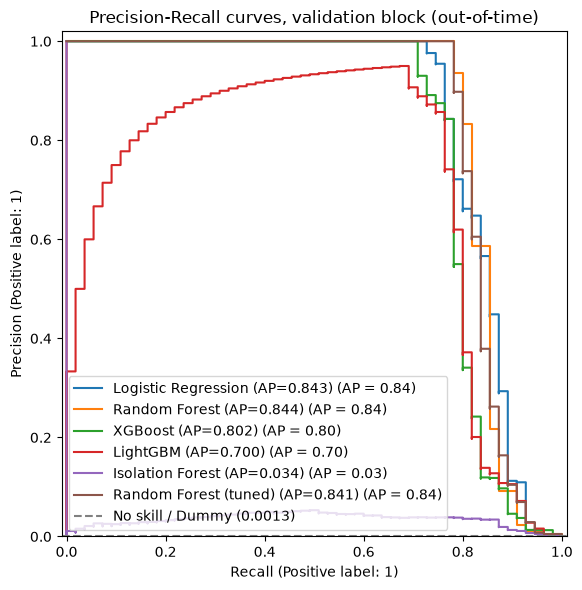

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, s in val_scores.items():
    if name == 'Dummy (prior)':
        continue                                                   # a flat line, drawn as "No skill" below
    PrecisionRecallDisplay.from_predictions(y_val, s, name=f'{name} (AP={average_precision_score(y_val, s):.3f})', ax=ax)
ax.axhline(y_val.mean(), color='gray', linestyle='--', label=f'No skill / Dummy ({y_val.mean():.4f})')
ax.set_title('Precision-Recall curves, validation block (out-of-time)')
ax.set_ylim(0, 1.02)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 8. Threshold Selection

By default `predict()` flags a transaction when its score is ≥ 0.5, but 0.5 has no special meaning for these models (and none at all for a model trained on resampled or re-weighted data).

The earlier argument was that a missed fraud costs far more than a false decline. Maximising **F1** does not reflect that, because F1 treats both errors symmetrically. Four rules are compared on the **validation** block:

| rule | idea |
|---|---|
| Default 0.5 | reference |
| Best F1 | symmetric trade-off between precision and recall |
| Best F2 | treats recall as twice as important as precision |
| **Minimum expected cost** | every alert costs `REVIEW_COST`; every *missed* fraud costs its actual `Amount` |

`REVIEW_COST` is an assumption (analyst time + customer friction), so a sensitivity table shows how the optimal threshold moves with it. The cost curve is also usually **flat** near the optimum, so treat the threshold as a range rather than a precise point. The chosen threshold is frozen here, and the test block is never used to adjust it.

,threshold,precision,recall,F1,alerts_per_10k,fraud_value_caught_%,expected_cost
Default 0.5,0.50,1.000,0.764,0.866,9.869,83.328,1609.83
Best F1,0.49,1.000,0.782,0.878,10.104,95.193,618.56
Best F2,0.38,0.936,0.800,0.863,11.043,95.220,636.34
Min expected cost (review=5),0.20,0.588,0.855,0.696,18.797,98.265,545.69


Expected cost with no model (nothing flagged): 8,396
Thresholds within 5% of the minimum cost span 0.20 to 0.20 (a wide range means the exact value is not critical)


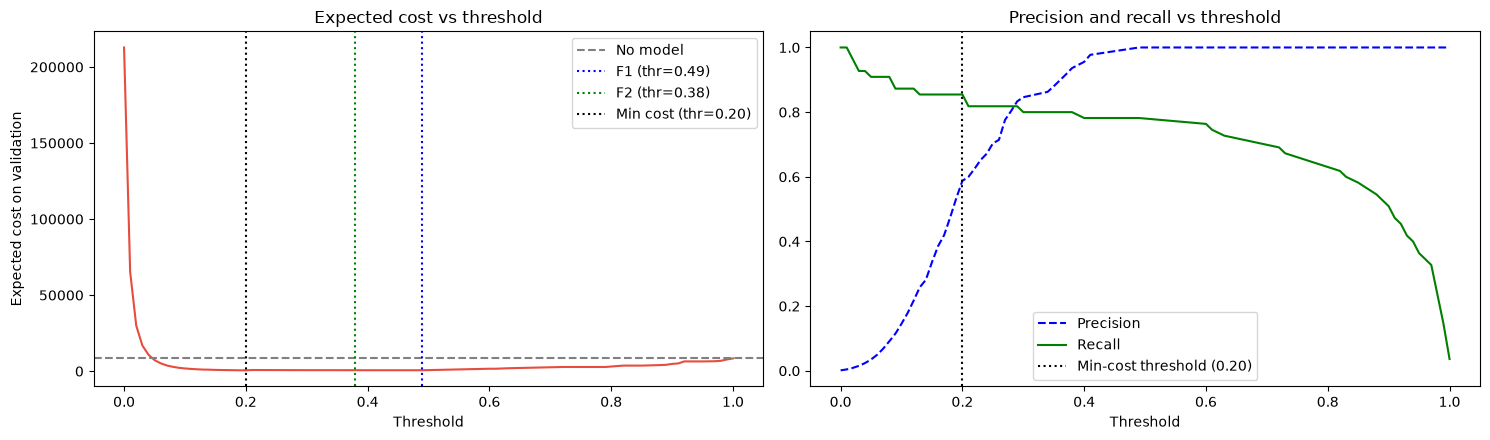

,best_threshold,recall,precision,alerts_per_10k
review_cost,,,,
1,0.20,0.855,0.588,18.797
5,0.20,0.855,0.588,18.797
20,0.49,0.782,1.000,10.104
50,0.49,0.782,1.000,10.104
100,0.49,0.782,1.000,10.104



Chosen operating threshold: 0.200


In [25]:
final_val = val_scores[final_name]

# Candidate thresholds
thr_f1, _ = best_fbeta_threshold(y_val, final_val, beta=1)
thr_f2, _ = best_fbeta_threshold(y_val, final_val, beta=2)
thr_grid, cost = cost_curve(y_val, final_val, amt_val, REVIEW_COST)
thr_cost = float(thr_grid[np.argmin(cost)])
no_model_cost = float((amt_val * y_val.values).sum())                 # nothing flagged: every fraud is lost

rules = {'Default 0.5': 0.5, 'Best F1': thr_f1, 'Best F2': thr_f2,
         f'Min expected cost (review={REVIEW_COST:g})': thr_cost}
table = {}
for rule, thr in rules.items():
    r = evaluate(y_val, final_val, amt_val, thr)
    table[rule] = {'threshold': thr, 'precision': r['precision'], 'recall': r['recall'], 'F1': r['f1'],
                   'alerts_per_10k': r['alerts_per_10k'], 'fraud_value_caught_%': r['fraud_value_caught_%'],
                   'expected_cost': r['expected_cost']}
display(pd.DataFrame(table).T.round(3))
print(f'Expected cost with no model (nothing flagged): {no_model_cost:,.0f}')

near = thr_grid[cost <= cost.min() * 1.05]
print(f'Thresholds within 5% of the minimum cost span {near.min():.2f} to {near.max():.2f} '
      f'(a wide range means the exact value is not critical)')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(thr_grid, cost, color='#e74c3c')
ax[0].axhline(no_model_cost, color='gray', linestyle='--', label='No model')
for label, thr, color in [('F1', thr_f1, 'blue'), ('F2', thr_f2, 'green'), ('Min cost', thr_cost, 'black')]:
    ax[0].axvline(thr, color=color, linestyle=':', label=f'{label} (thr={thr:.2f})')
ax[0].set_xlabel('Threshold')
ax[0].set_ylabel('Expected cost on validation')
ax[0].set_title('Expected cost vs threshold')
ax[0].legend()

prec, rec, thr_pr = precision_recall_curve(y_val, final_val)
ax[1].plot(thr_pr, prec[:-1], 'b--', label='Precision')
ax[1].plot(thr_pr, rec[:-1], 'g-', label='Recall')
ax[1].axvline(thr_cost, color='black', linestyle=':', label=f'Min-cost threshold ({thr_cost:.2f})')
ax[1].set_xlabel('Threshold')
ax[1].set_title('Precision and recall vs threshold')
ax[1].legend()
plt.tight_layout()
plt.show()

# Sensitivity: how does the optimal threshold move with the assumed cost of a review?
sens = []
for rc in [1, 5, 20, 50, 100]:
    tg, c = cost_curve(y_val, final_val, amt_val, rc)
    t_opt = float(tg[np.argmin(c)])
    r = evaluate(y_val, final_val, amt_val, t_opt, review_cost=rc)
    sens.append({'review_cost': rc, 'best_threshold': t_opt, 'recall': r['recall'],
                 'precision': r['precision'], 'alerts_per_10k': r['alerts_per_10k']})
display(pd.DataFrame(sens).set_index('review_cost').round(3))

thr_final = thr_cost        # operating point used on the test block. It is fixed from here on.
print(f'\nChosen operating threshold: {thr_final:.3f}')

#### Interpretation

The classification report summarizes the model's precision, recall, and F1-score for each class.

Because fraud detection is an imbalanced classification problem, particular attention is given to the **Fraud** class rather than overall accuracy.

In [29]:
print(f"ROC-AUC Score:           {roc_auc_score(y_test, y_prob):.4f}")
print(f"PR-AUC Score (Avg Prec): {average_precision_score(y_test, y_prob):.4f}")

ROC-AUC Score:           0.9664
PR-AUC Score (Avg Prec): 0.8020


#### Performance Metrics

- **ROC-AUC** measures the model's ability to distinguish between legitimate and fraudulent transactions.
- **PR-AUC** focuses on the balance between precision and recall and is more informative for highly imbalanced datasets.

For fraud detection, PR-AUC is considered the more appropriate metric.

### Visualization of Model Performance

The following visualizations provide a comprehensive assessment of the selected model by illustrating:

- Classification performance
- ROC Curve
- Precision-Recall Curve
- Cross-validation comparison

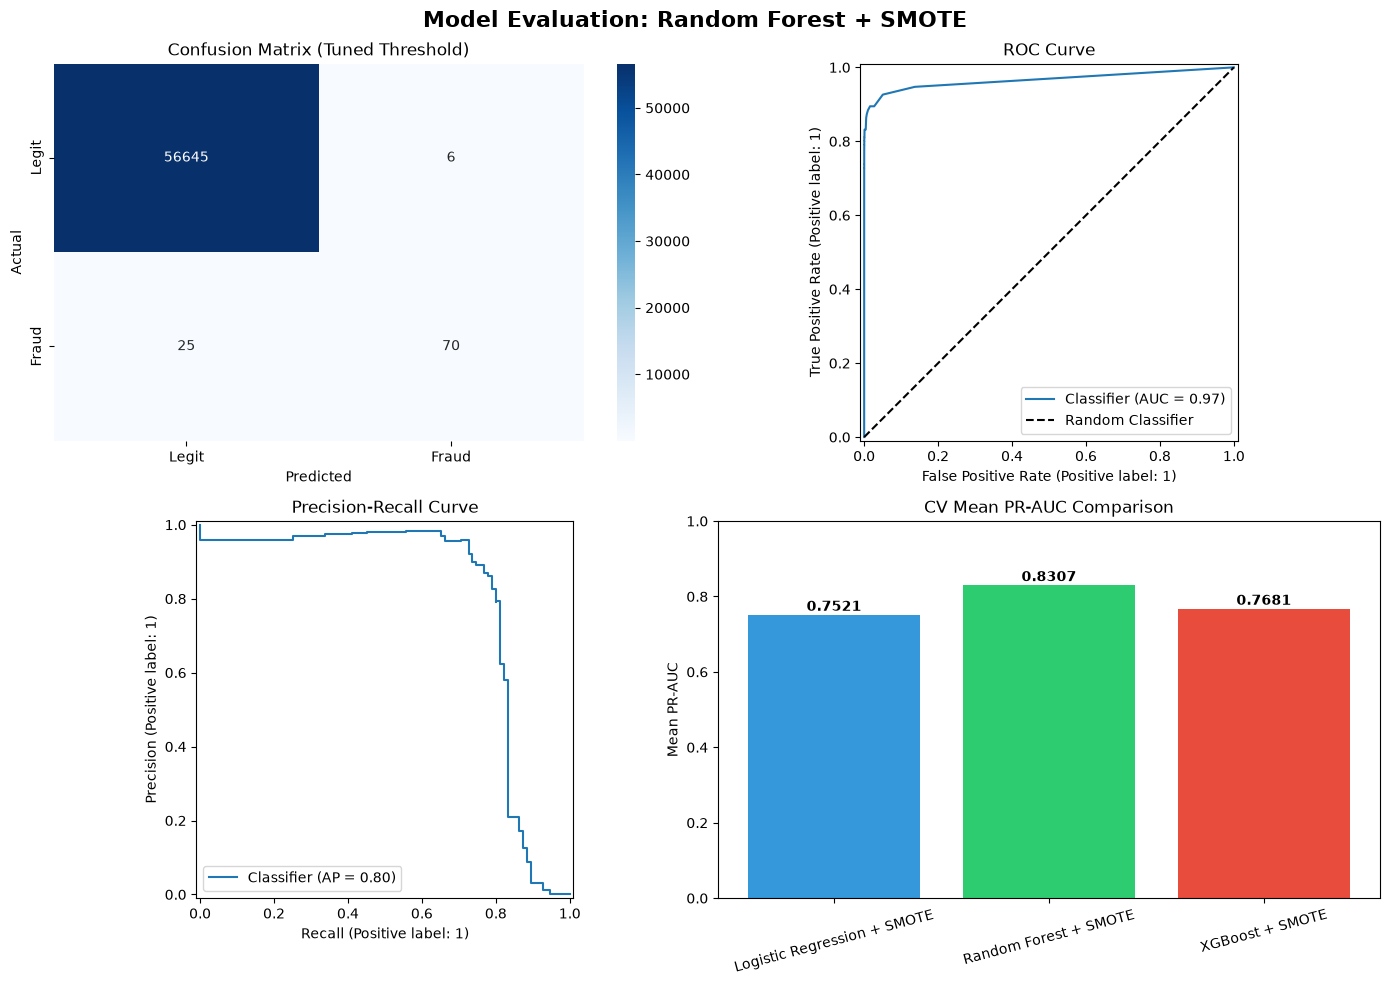

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Model Evaluation: {best_name}', fontsize=16, fontweight='bold')

# ── 1. Confusion matrix ───────────────────────────────────────────────────────
ax1 = axes[0, 0]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=['Legit', 'Fraud'],
            yticklabels=['Legit', 'Fraud'])
ax1.set_title('Confusion Matrix (Tuned Threshold)')
ax1.set_ylabel('Actual')
ax1.set_xlabel('Predicted')

# ── 2. ROC curve ──────────────────────────────────────────────────────────────
ax2 = axes[0, 1]
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax2)
ax2.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
ax2.set_title('ROC Curve')
ax2.legend()

# ── 3. Precision-Recall curve ─────────────────────────────────────────────────
ax3 = axes[1, 0]
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=ax3)
ax3.set_title('Precision-Recall Curve')

# ── 4. CV results comparison ──────────────────────────────────────────────────
ax4 = axes[1, 1]
model_names = list(cv_results.keys())
model_scores = list(cv_results.values())
bars = ax4.bar(model_names, model_scores, color=['#3498db', '#2ecc71', '#e74c3c'])
ax4.set_title('CV Mean PR-AUC Comparison')
ax4.set_ylabel('Mean PR-AUC')
ax4.set_ylim(0, 1)
for bar, score in zip(bars, model_scores):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{score:.4f}', ha='center', fontweight='bold')
ax4.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

### Observations

- The confusion matrix indicates that the model correctly classifies the vast majority of legitimate transactions while successfully identifying most fraudulent transactions.
- The ROC curve demonstrates strong discrimination capability, with an ROC-AUC close to 1.
- The Precision-Recall curve confirms that the classifier maintains a good balance between precision and recall despite the severe class imbalance.
- Cross-validation results show that the Random Forest pipeline achieved the highest average PR-AUC, making it the most suitable model for this dataset.

In [34]:
# Save the best model
import joblib
joblib.dump(best_pipeline, 'fraud_pipeline.joblib')

['fraud_pipeline.joblib']

In [35]:
# Getting sample.csv
sample = pd.concat([
    df[df['Class'] == 0].sample(15, random_state=42),
    df[df['Class'] == 1].sample(5, random_state=42)
])
sample.to_csv('sample.csv', index=False)

## 9. Conclusion

This project developed and evaluated multiple machine learning models for detecting fraudulent credit card transactions.

### Summary of the workflow

- Explored and analyzed the dataset using EDA.
- Verified data quality by checking missing values and duplicate records.
- Applied feature scaling and SMOTE within machine learning pipelines to address class imbalance while preventing data leakage.
- Compared Logistic Regression, Random Forest, and XGBoost using Stratified Cross-Validation.
- Selected the best-performing model based on the Average Precision (PR-AUC) score.
- Evaluated the selected model on an unseen test set using multiple performance metrics.

### Final Results

- Best Model: **Random Forest + SMOTE**
- Cross-Validation PR-AUC: **0.8274**
- Test ROC-AUC: **0.9694**
- Test PR-AUC: **0.8115**

### Key Findings

- The Random Forest pipeline achieved the strongest overall performance among the evaluated models.
- PR-AUC proved to be a more informative evaluation metric than accuracy because of the severe class imbalance.
- Combining feature scaling, SMOTE, and ensemble learning produced a robust fraud detection model capable of identifying fraudulent transactions with high precision and recall.


### Improvments

**Out-of-Time (OOT) Split:** Sorted data by time and split the data into Train (70%), Validation (15%), and Test (15%).
- Because the dataset includes a Time feature (seconds elapsed), randomly splitting the data means model might be training on transactions from Day 2 to predict a transaction on Day 1. In reality, you can never predict the past using the future.
- This mimics how a real fraud system is deployed in production.

In [36]:
# --- 1. OUT-OF-TIME (OOT) SPLIT ---
print("Restructuring data for Out-of-Time (OOT) Validation...")

# Sort by Time to simulate real-world production data streams
df_oot = df.sort_values('Time').copy()

X_oot = df_oot.drop('Class', axis=1)
y_oot = df_oot['Class']

# Calculate indices for 70% Train, 15% Validation, 15% Test
train_idx = int(len(X_oot) * 0.70)
val_idx = int(len(X_oot) * 0.85)

# Split the data chronologically
X_train_oot, y_train_oot = X_oot.iloc[:train_idx], y_oot.iloc[:train_idx]
X_val_oot, y_val_oot = X_oot.iloc[train_idx:val_idx], y_oot.iloc[train_idx:val_idx]
X_test_oot, y_test_oot = X_oot.iloc[val_idx:], y_oot.iloc[val_idx:]

print(f"Train set (Past):        {X_train_oot.shape}")
print(f"Validation set (Future): {X_val_oot.shape}")
print(f"Test set (Far Future):   {X_test_oot.shape}")

# Re-traininig best pipeline (Random Forest + SMOTE) on the new OOT Train set
print("\nTraining best model on OOT Train set...")
best_pipeline.fit(X_train_oot, y_train_oot)
print("Training complete!")

Restructuring data for Out-of-Time (OOT) Validation...
Train set (Past):        (198608, 30)
Validation set (Future): (42559, 30)
Test set (Far Future):   (42559, 30)

Training best model on OOT Train set... (This might take a minute)
Training complete!


**Threshold Optimization:** By default, .predict() uses a 0.5 (50%) probability threshold. In fraud, a False Negative (missing a $5,000 fraud) costs way more than a False Positive (declining a $5 coffee).
- We are going to predict probabilities on our Validation set and test every single threshold to find the one that gives us the best F1-score.

Optimizing classification threshold on Validation Set...
Default (0.5) Threshold F1: 0.8571
Optimized Threshold: 0.4500
Optimized F1-score:  0.8600


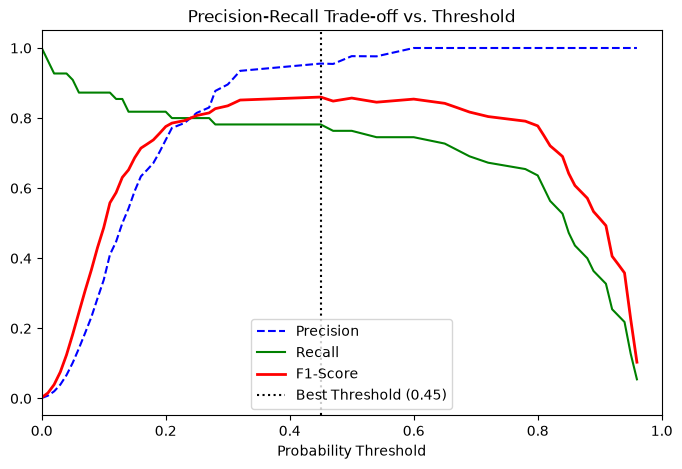

In [37]:
from sklearn.metrics import precision_recall_curve

print("Optimizing classification threshold on Validation Set...")

# Get probabilities for the Validation set
val_probs = best_pipeline.predict_proba(X_val_oot)[:, 1]

# Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_val_oot, val_probs)

# Calculate F1-score for each threshold
# Adding 1e-10 to the denominator prevents division by zero
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)

# Find the threshold that yields the maximum F1-score
best_idx = np.argmax(f1_scores)
optimized_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Default (0.5) Threshold F1: {f1_scores[np.abs(thresholds - 0.5).argmin()]:.4f}")
print(f"Optimized Threshold: {optimized_threshold:.4f}")
print(f"Optimized F1-score:  {best_f1:.4f}")

# Plot the Trade-off
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.plot(thresholds, f1_scores[:-1], 'r-', label='F1-Score', linewidth=2)
plt.axvline(x=optimized_threshold, color='k', linestyle=':', label=f'Best Threshold ({optimized_threshold:.2f})')
plt.title("Precision-Recall Trade-off vs. Threshold")
plt.xlabel("Probability Threshold")
plt.legend(loc='best')
plt.xlim([0, 1])
plt.show()

- Using my tuned threshold to final test set.

In [38]:
# --- 3. FINAL TEST EVALUATION ---
print(f"Evaluating on Test Set using Optimized Threshold ({optimized_threshold:.4f})...\n")

test_probs = best_pipeline.predict_proba(X_test_oot)[:, 1]
# Apply the optimized threshold instead of default 0.5
test_preds = (test_probs >= optimized_threshold).astype(int)

print("Classification Report:")
print(classification_report(y_test_oot, test_preds))

print("Confusion Matrix:")
cm = confusion_matrix(y_test_oot, test_preds)
print(f"TP: {cm[1,1]} | FN: {cm[1,0]}")
print(f"FP: {cm[0,1]} | TN: {cm[0,0]}\n")

Evaluating on Test Set using Optimized Threshold (0.4500)...

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42507
           1       0.85      0.75      0.80        52

    accuracy                           1.00     42559
   macro avg       0.92      0.87      0.90     42559
weighted avg       1.00      1.00      1.00     42559

Confusion Matrix:
TP: 39 | FN: 13
FP: 7 | TN: 42500



**Explainability with SHAP:** Black-box models are heavily regulated in finance. Implementing SHAP (SHapley Additive exPlanations) to visualize exactly why the random forest model flagged a specific transaction as fraud, will be important for real life decisions.
- I'll extract the model from pipeline and visualize why it flags certain transactions and see exactly which features drove model to call transaction fraud.


Generating SHAP Explanations...


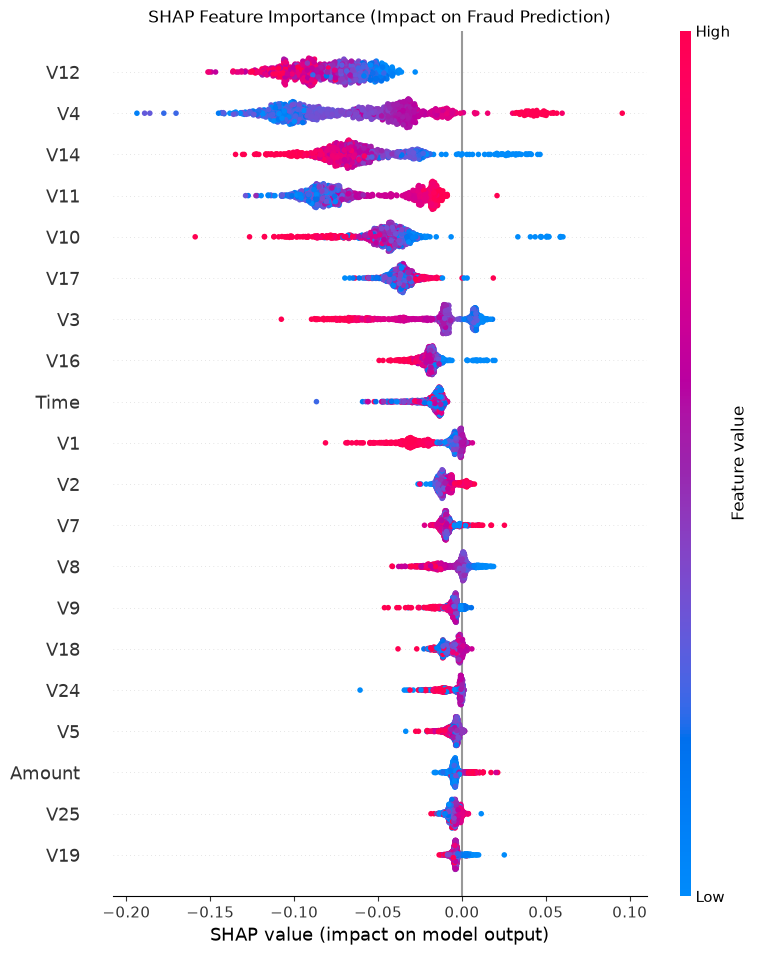

In [40]:
import shap

# --- 4. SHAP EXPLAINABILITY (CORRECTED) ---
print("Generating SHAP Explanations...")

# Extract the fitted model and scaler from the pipeline
rf_model = best_pipeline.named_steps['model']
scaler = best_pipeline.named_steps['scaler']

# We must scale the data first
X_test_scaled = scaler.transform(X_test_oot)

# Sample 1000 rows for the visualization
X_test_sample = pd.DataFrame(X_test_scaled, columns=X_test_oot.columns).sample(1000, random_state=42)

# Create the SHAP Explainer
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_sample)

# Safely extract Class 1 (Fraud) regardless of your SHAP version
if isinstance(shap_values, list):
    fraud_shap_values = shap_values[1]                 # Old SHAP versions
elif len(shap_values.shape) == 3:
    fraud_shap_values = shap_values[:, :, 1]           # New SHAP versions
else:
    fraud_shap_values = shap_values                    # Fallback for XGBoost

# Generate the plot
shap.summary_plot(fraud_shap_values, X_test_sample, feature_names=X_test_oot.columns, show=False)

# Add title AFTER calling summary_plot, then show
plt.title("SHAP Feature Importance (Impact on Fraud Prediction)")
plt.show()

### SHAP Feature Importance Analysis

* **Top Drivers of Fraud:** Features **V12**, **V4**, and **V14** are the three most influential variables in determining whether a transaction is fraudulent. 
* **Direct Relationships:** For features **V4** and **V11**, high feature values (shown in red) result in positive SHAP values, meaning they strongly push the model's prediction toward fraud. 
* **Inverse Relationships:** For features like **V12**, **V14**, **V10**, **V17**, and **V3**, lower feature values (shown in blue) yield positive SHAP values, driving the fraud prediction. Conversely, high values (red) for these features push the model toward a legitimate classification (negative SHAP values).
* **Magnitude of Impact:** The horizontal spread of points shows how drastically a feature shifts the prediction. For instance, extreme high values in **V4** stretch far to the right (up to roughly 0.10), showing a severe, isolated impact on the model flagging a transaction as fraud.

**Explanation:**
This SHAP summary plot decodes the black-box nature of our model by showing not just *which* features matter most, but exactly *how* they influence the final decision. Because the original dataset was anonymized using PCA, we do not know the real-world financial metrics behind V12 or V4. However, the model has clearly mapped out a strict mathematical fingerprint for malicious activity. 

According to the plot, a transaction exhibiting an abnormally high V4 value combined with abnormally low V12 and V14 values is the strongest indicator of fraud in this dataset. Implementing this level of explainability is a crucial requirement in financial technology for regulatory compliance, customer transparency, and diagnosing false positives.